# Exercise 17.1 - Solution
## Speckle removal with denoising autoencoders (DAEs)
Small-angle scattering of X-rays or neutrons enables insights into properties of nanostructured materials.
In the case of X-rays from undulators at synchrotron radiation sources, extreme beam focusing can result in a high degree of coherence. Interference effects called speckles then appear naturally in the recorded data.
This may be an unwanted effect that makes the measurements appear noisy.  

Try to remove the speckles from the given test samples:
 1. Set up and train a deep convolutional autoencoder.
 2. State the test loss and comment on the reconstruction results for some test images.
 3. Apply the autoencoder to experimental data from partially coherent illumination and describe your observations.

Training DAEs on the provided data can be computationally demanding, thus, we recommend to use a GPU for this task.

In [ ]:
!pip install torchviz

  Preparing metadata (setup.py) ... done
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (23.7 MB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (823 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (14.1 MB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl (731.7 MB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl (410.6 MB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl (121.6 MB)
  Using cached nvidia_curand_cu12-10.3.2.106-py3-none-manylinux1_x86_64.whl (56.5 MB)
  Using cached nvidia_cusolver_cu12-11.4.5.107-py3-none-manylinux1_x86_64.whl (124.2 MB)
  Using cached nvidia_cusparse_cu12-12.1.0.106-py3-none-manylinux1_x86_64.whl (196.0 MB)
  Using cached nvidia_nccl_cu12-2.20.5-py3-none-manylinux2014_x86_64.whl (176.2 MB)
  Using cached nvidia_nvtx_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (99 kB)
     ━━━━━━━

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from torchvision import transforms
import torchvision.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torchsummary import summary

import torchviz
from torchviz import make_dot

In [ ]:

"""Download the speckle image dataset into the local data directory.

The notebook is intended to run from the repository root.
The dataset is downloaded only if it is not already available.
"""

from pathlib import Path
import gdown

# Repository root: directory from which the notebook is running
PROJECT_DIR = Path.cwd()

# Input data and generated figures
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Dataset provided with the original textbook exercise
FILE_ID = "1CJVbIkLmzDTfC6ftaIUPiuqjoC0ay-wr"

output = DATA_DIR / "speckles.npz"

if not output.exists():
    print("Downloading speckle dataset...")
    gdown.download(
        id=FILE_ID,
        output=str(output),
        quiet=False,
    )
else:
    print(f"Using existing dataset: {output}")

if not output.exists():
    raise FileNotFoundError(
        f"Dataset not found: {output}"
    )

print(f"Dataset path: {output}")
print(f"Figures directory: {FIGURES_DIR}")


Downloading...
From: https://drive.google.com/u/0/uc?export=download&confirm=HgGH&id=1CJVbIkLmzDTfC6ftaIUPiuqjoC0ay-wr
To: /content/speckles.npz
100%|██████████| 232M/232M [00:04<00:00, 47.7MB/s]


### Preprocess data

In [ ]:
# Load paired target and speckled scattering images
with np.load(output) as data:
    image_normal = data["target_images"]
    image_speckle = data["speckle_images"]

print(f"Target images: {image_normal.shape}")
print(f"Speckled images: {image_speckle.shape}")

# logarithmic intensity values
image_normal = np.log10(image_normal + 1.)
image_speckle = np.log10(image_speckle + 1.)

# norm input data to max. value of distorted scattering pattern
max_val = np.max(image_speckle, axis=(1, 2, 3), keepdims=True)

image_normal = image_normal / max_val
image_normal = np.clip(image_normal, 0., 1.1)  # limit maximum intensity values

image_speckle = image_speckle / max_val
image_speckle = np.clip(image_speckle, 0., 1.1)  # limit maximum intensity values

In [ ]:
n_train = 20000             # number of training samples
n = image_normal.shape[0]

# Create training, validation, and test datasets
x_train_noisy, x_test_noisy = image_speckle[0:n_train], image_speckle[n_train:]
x_train, x_test = image_normal[0:n_train], image_normal[n_train:]

# Transforming to Pytorch tensors
x_train_noisy = torch.tensor(x_train_noisy, dtype=torch.float32).permute(0, 3, 1, 2)
x_test_noisy = torch.tensor(x_test_noisy, dtype=torch.float32).permute(0, 3, 1, 2)

x_train = torch.tensor(x_train, dtype=torch.float32).permute(0, 3, 1, 2)
x_test = torch.tensor(x_test, dtype=torch.float32).permute(0, 3, 1, 2)

### Plot example data

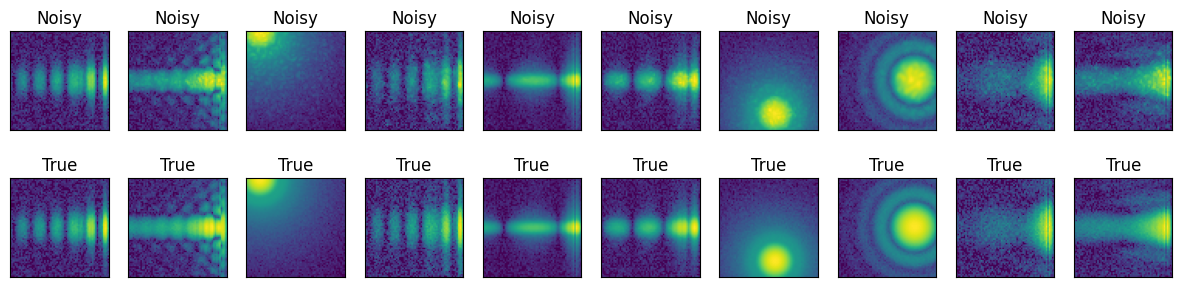

In [ ]:
plots = 10
plt.figure(1, (15, 3.5))
idx = np.random.choice(n, 10)

for i in range(plots):
    plt.subplot(2, plots, i+1)
    plt.imshow(image_speckle[idx[i],:,:,0])
    plt.xticks([])
    plt.yticks([])
    plt.title("Noisy")

    plt.subplot(2, plots, plots+i+1)
    plt.imshow(image_normal[idx[i],:,:,0])
    plt.xticks([])
    plt.yticks([])
    plt.title("True")

plt.show()

## Model building

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

        self.relu = nn.ReLU()

        # Define the encoder layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.maxpool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.convenc = nn.Conv2d(64, 64, kernel_size=3, padding = 1)

        # Define the decoder layers
        self.upsample1 = nn.Upsample(scale_factor=2)
        self.conv5 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv7 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.upsample2 = nn.Upsample(scale_factor=2)
        self.conv8 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv9 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv10 = nn.Conv2d(32, 1, kernel_size=3, padding=1)

    def forward(self, x):
        # Encoder part
        x = self.conv1(x)
        x = self.relu(x)
        x = self.conv2(x)
        x1 = self.relu(x)
        x = self.maxpool1(x1)
        x = self.conv3(x)
        x = self.relu(x)
        x = self.conv4(x)
        x2 = self.relu(x)
        x = self.maxpool2(x2)
        x = self.convenc(x)
        x = self.relu(x)

        # Decoder part
        x = self.upsample1(x)
        x = self.conv5(x)
        x = self.relu(x)
        x = self.conv6(x)
        x2_2 = self.relu(x)
        x = x2 + x2_2
        x = self.upsample2(x)
        x = self.conv7(x)
        x = self.relu(x)
        x = self.conv8(x)
        x1_2 = self.relu(x)
        x = x1 + x1_2
        x = self.conv9(x)
        x = self.conv10(x)

        return x

# Instantiate the model and move it to the appropriate device
model = Autoencoder()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Print model summary with input shapes
def print_summary(model, input_size):
    print("Connected to")
    print("Input size:", input_size)
    layer_idx = 0          #layer index: to keep track of the index of the layers in the model
    for layer in model.children():  # iterator over all immediate submodules(layers)
        if isinstance(layer, nn.Conv2d) or isinstance(layer, nn.MaxPool2d) or isinstance(layer, nn.Upsample): #checks if the current layer is an instance of one of the specified layer types
            layer_idx += 1  #If the current layer is one of the specified types then +1 to keep track of the layer index
            print("Layer", layer_idx, ": ", end="")
            if isinstance(layer, nn.Conv2d):
                print("Conv2d", end="")
            elif isinstance(layer, nn.MaxPool2d):
                print("MaxPool2d", end="")
            elif isinstance(layer, nn.Upsample):
                print("Upsample", end="")
            print(" -> ", end="")
            if layer_idx == 1:
                print("Input", end="")
            else:
                print("Layer", layer_idx - 1, end="")
            print()

print_summary(model, (1, 64, 64))
summary(model, (1, 64, 64))


Connected to
Input size: (1, 64, 64)
Layer 1 : Conv2d -> Input
Layer 2 : Conv2d -> Layer 1
Layer 3 : MaxPool2d -> Layer 2
Layer 4 : Conv2d -> Layer 3
Layer 5 : Conv2d -> Layer 4
Layer 6 : MaxPool2d -> Layer 5
Layer 7 : Conv2d -> Layer 6
Layer 8 : Upsample -> Layer 7
Layer 9 : Conv2d -> Layer 8
Layer 10 : Conv2d -> Layer 9
Layer 11 : Conv2d -> Layer 10
Layer 12 : Upsample -> Layer 11
Layer 13 : Conv2d -> Layer 12
Layer 14 : Conv2d -> Layer 13
Layer 15 : Conv2d -> Layer 14
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             320
              ReLU-2           [-1, 32, 64, 64]               0
            Conv2d-3           [-1, 32, 64, 64]           9,248
              ReLU-4           [-1, 32, 64, 64]               0
         MaxPool2d-5           [-1, 32, 32, 32]               0
            Conv2d-6           [-1, 64, 32, 32]          18,496
           

In [ ]:
model.to(device)

Autoencoder(
  (relu): ReLU()
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (convenc): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (upsample1): Upsample(scale_factor=2.0, mode='nearest')
  (conv5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv7): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (upsample2): Upsample(scale_factor=2.0, mode='nearest')
  (conv8): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1)

#### Plot model to visualize the shortcuts

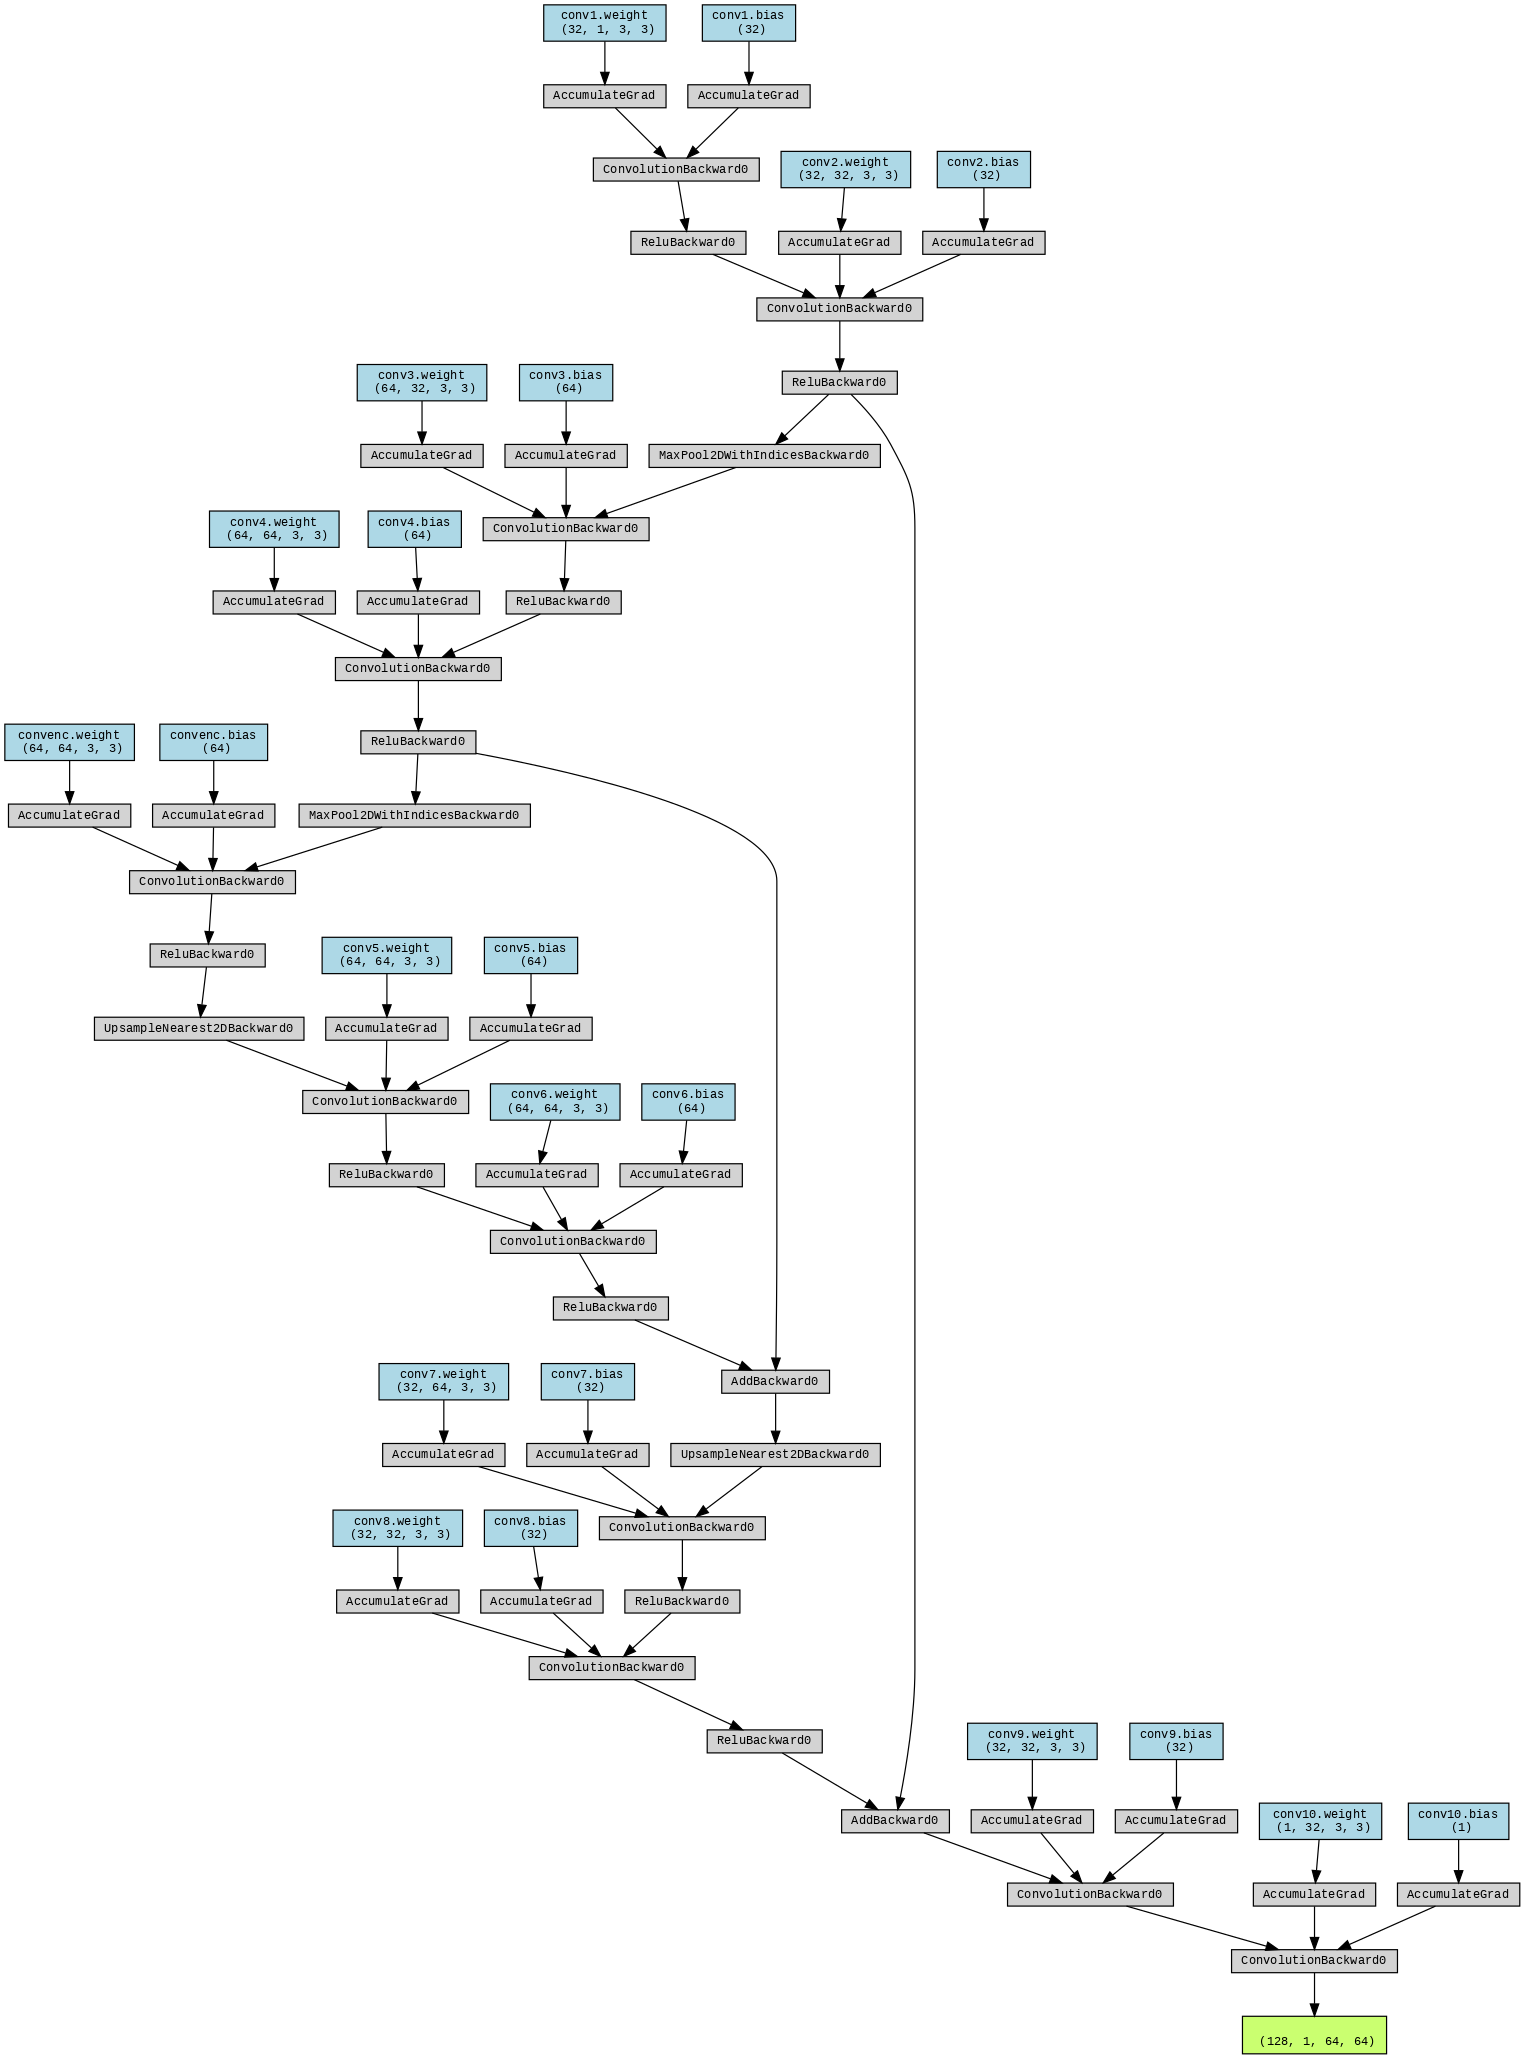

In [ ]:

"""Visualize the PyTorch autoencoder architecture.

Save the computation graph to figures/autoencoder_graph.png
and display it inside the notebook.
"""

import torch
from torchviz import make_dot
from IPython.display import Image, display

# Ensure the model and input are on the same device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

# Use a single example to generate the model graph
x = torch.randn(1, 1, 64, 64, device=device)

# Generate the computation graph
model.eval()
dot = make_dot(
    model(x),
    params=dict(model.named_parameters())
)

# Save to the repository figures directory
graph_path = dot.render(
    filename="autoencoder_graph",
    directory=str(FIGURES_DIR),
    format="png",
    cleanup=True,
)

print(f"Model graph saved to: {graph_path}")

# Display the generated graph
display(Image(filename=graph_path))


#### Compile and train the DAE

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.001)  #optimizer
criterion = nn.MSELoss()                              #loss function

# Convert numpy arrays to PyTorch tensors
train_data = TensorDataset(torch.Tensor(x_train_noisy), torch.Tensor(x_train))
val_data = TensorDataset(torch.Tensor(x_test_noisy), torch.Tensor(x_test))

# Define your DataLoader objects
train_loader = DataLoader(dataset=train_data, batch_size=128, shuffle=True)
val_loader = DataLoader(dataset=val_data, batch_size=128, shuffle=False)

train_losses = []
val_losses = []

# Training loop
for epoch in range(15):
  # Training
  model.train()
  train_loss = 0.0
  for batch_data in train_loader:
      # Forward pass
      inputs = batch_data[0].to(device)  # Move batch data to device
      denoised_input = batch_data[1].to(device)
      optimizer.zero_grad()   #clears the gradients of all optimized parameters
      outputs = model(inputs)

      loss = criterion(outputs, denoised_input) #loss

      loss.backward()         #computes gradients of the loss with respect to all parameters.
      optimizer.step()        #updates model parameters/weights based on the computed gradients using Adam

      train_loss += loss.item() * inputs.size(0)
      #Overall training loss

  # Average training loss
  train_loss /= len(train_loader.dataset)   #average loss per sample for the current epoch
  train_losses.append(train_loss)           #track how the training loss changes over the course of training

  # Validation
  model.eval()
  val_loss = 0.0
  with torch.no_grad():
      for batch_data in val_loader:
          inputs = batch_data[0].to(device)  # Move batch data to device
          denoised_input = batch_data[1].to(device)
          outputs = model(inputs)

          loss = criterion(outputs, denoised_input)

          val_loss += loss.item() * inputs.size(0)

  # Compute average validation loss
  val_loss /= len(val_loader.dataset)
  val_losses.append(val_loss)

  # Print training progress
  print("Epoch {} - Training Loss: {:.6f}, Validation Loss: {:.6f}".format(epoch+1, train_loss, val_loss))

Epoch 1 - Training Loss: 0.005332, Validation Loss: 0.000665
Epoch 2 - Training Loss: 0.000578, Validation Loss: 0.000599
Epoch 3 - Training Loss: 0.000484, Validation Loss: 0.000470
Epoch 4 - Training Loss: 0.000450, Validation Loss: 0.000450
Epoch 5 - Training Loss: 0.000434, Validation Loss: 0.000420
Epoch 6 - Training Loss: 0.000427, Validation Loss: 0.000475
Epoch 7 - Training Loss: 0.000415, Validation Loss: 0.000407
Epoch 8 - Training Loss: 0.000404, Validation Loss: 0.000395
Epoch 9 - Training Loss: 0.000410, Validation Loss: 0.000390
Epoch 10 - Training Loss: 0.000401, Validation Loss: 0.000386
Epoch 11 - Training Loss: 0.000390, Validation Loss: 0.000381
Epoch 12 - Training Loss: 0.000391, Validation Loss: 0.000393
Epoch 13 - Training Loss: 0.000390, Validation Loss: 0.000387
Epoch 14 - Training Loss: 0.000392, Validation Loss: 0.000371
Epoch 15 - Training Loss: 0.000381, Validation Loss: 0.000377


The training loop repeats for each batch in the training dataset within each epoch, updating the model parameters based on the computed gradients and accumulating the training loss. At the end of each epoch, the average training loss is typically computed and monitored to track the training progress and model performance.

Don't need to define batch_data explicitly before iterating over batches. The DataLoader handles the process of providing batches of data during each iteration of the training loop automatically.

### Plot training history

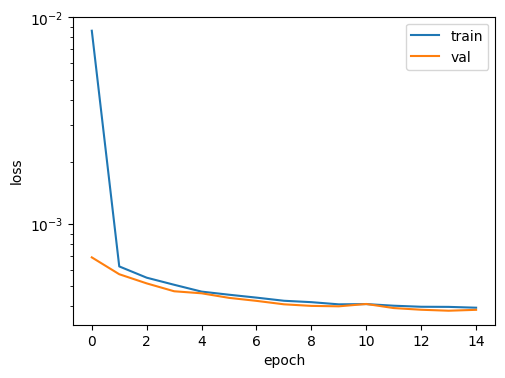

In [ ]:

"""Plot and save training and validation loss."""

fig, ax = plt.subplots(figsize=(7, 4))

epochs = np.arange(1, len(train_losses) + 1)

ax.plot(
    epochs,
    train_losses,
    label="Training loss",
    linewidth=1.5,
)

ax.plot(
    epochs,
    val_losses,
    label="Validation loss",
    linewidth=1.5,
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error")
ax.set_yscale("log")
ax.legend(frameon=False)

fig.tight_layout()

plot_path = FIGURES_DIR / "training_validation_loss.pdf"

fig.savefig(plot_path, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved figure to: {plot_path}")


### Investigate the DAE performance using the test data

In [ ]:
#preds = autoencoder.predict(x_test_noisy, verbose=1)
model.eval()
x_test_noisy_tensor = torch.Tensor(x_test_noisy).to(device)
with torch.no_grad():  # Disable gradient computation
    preds = model(x_test_noisy_tensor[:200])
preds = preds.cpu().numpy()

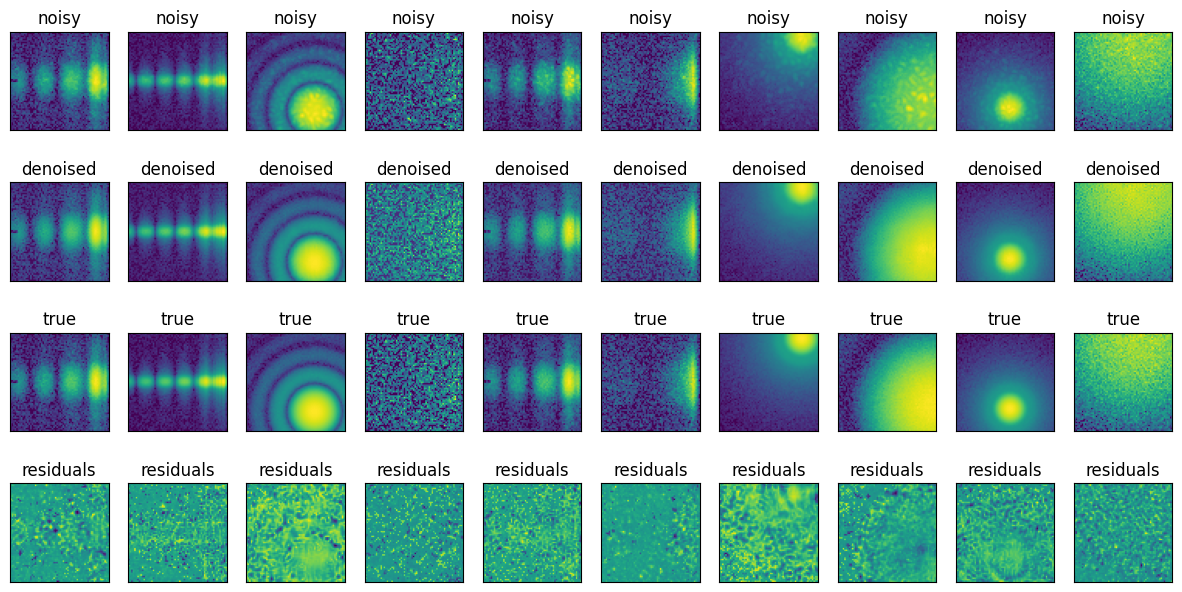

In [ ]:
plots = 10
n_test = x_test.shape[0]
n_test = 200
fig = plt.figure(figsize=(15, 7.5))
idx = np.random.choice(n_test, 10)  #randomly selects 10 indices from the test data to use for visualization

with torch.no_grad():
  for i in range(plots):
    plt.subplot(4, plots, i+1)
    plt.imshow(x_test_noisy[idx[i],0,:,:])
    plt.xticks([])
    plt.yticks([])
    plt.title("noisy")  #shows the noisy input image

    plt.subplot(4, plots, plots+i+1)
    plt.imshow(preds[idx[i],0,:,:])
    plt.xticks([])
    plt.yticks([])
    plt.title("denoised") #shows the denoised output image

    plt.subplot(4, plots, 2*plots+i+1)
    plt.imshow(x_test[idx[i],0,:,:])
    plt.xticks([])
    plt.yticks([])
    plt.title("true") #shows the true (original) image

    plt.subplot(4, plots, 3*plots+i+1)
    plt.imshow(x_test[idx[i],0,:,:] - preds[idx[i],0,:,:])
    plt.xticks([])
    plt.yticks([])
    plt.title("residuals")    #shows the difference between the true image and the denoised image

fig.tight_layout()

plot_path = FIGURES_DIR / "denoising_reconstructions.pdf"

fig.savefig(plot_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print(f"Saved reconstruction figure to: {plot_path}")